# Who Keeps Texas On After Dark?

Day 17 · Light & dark. One sunny day on ERCOT, Texas's main grid, hour by hour. Every power plant shifts from grey
to full colour as its fuel's output across the grid rises toward the day's peak.
Run `python scripts\fetch_week3.py day13 day17` first.

## 1 · Settings

In [2]:
DAY      = 17
PROMPT   = "Light & dark"
SLUG     = "light-dark-texas-grid"
NOTEBOOK = "day17_light_dark_texas_grid.ipynb"
TITLE    = "Texas Power Mix,\nDay and Night"
SUBTITLE = None          # None = written from the data (the day's share of renewables)
CREDITS  = ("Hourly generation by fuel: U.S. Energy Information Administration, Form EIA-930 (ERCOT). "
            "Power plants: EIA-860M (September 2026). Texas boundary and counties: US Census Bureau.")

THE_DAY  = None          # None = the sunniest day in the file (most solar MWh). Or a date like "07/15/2026"
FPS      = 15
PER_HOUR = 9             # frames for each hour of the day (more = slower, smoother)
HOLD     = 2.0           # seconds to pause on the last frame

PAGE, INK, SOFT = "#0c1016", "#f1ede4", "#8b949c"
LAND, IDLE = "#161e2a", "#4a525c"        # Texas stays this colour; plants fade to IDLE grey when their fuel is resting
SUBTITLE_WIDTH = 46                      # characters per line in the subtitle paragraph
FUELS = {   # fuel: (colour, label). Plants of other fuels sit as faint dots.
    "Gas":     ("#ff7a3d", "Gas"),
    "Solar":   ("#ffd34d", "Solar"),
    "Wind":    ("#6ee7d2", "Wind"),
    "Storage": ("#b38cff", "Batteries"),
}
CITIES = {"Houston": (29.760, -95.370), "Dallas": (32.777, -96.797), "Fort Worth": (32.755, -97.331),
          "San Antonio": (29.424, -98.494), "Austin": (30.267, -97.743), "El Paso": (31.759, -106.487),
          "Corpus Christi": (27.800, -97.396), "Lubbock": (33.578, -101.855), "Amarillo": (35.222, -101.831),
          "Midland": (31.997, -102.078)}
OTHER = {"Coal": "#a1887f", "Nuclear": "#e7e7e7", "Hydro": "#4fa3e0", "Oil": "#c0573e", "Other": "#7b858c"}

## 2 · Load

In [3]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
from mapkit import ai, poster, publish
from mapkit.paths import PROCESSED

hourly = pd.read_csv(PROCESSED / "ercot_hourly_fuel.csv", parse_dates=["utc_end"])
gens = pd.read_csv(PROCESSED / "eia860m_generators.csv")
texas = ai.load_states().query("state_abb == 'TX'").to_crs(4326)
tx_counties = gpd.read_file(PROCESSED / "counties_connectivity.geojson").query("state_abb == 'TX'").to_crs(4326)

gens = gens[(gens.ba == "ERCO") & (gens.status_group == "operating") & ~gens.status.str.startswith("(OS)")]
plants = gens.groupby(["plant_id", "fuel"]).agg(mw=("mw", "sum"), lat=("lat", "first"), lon=("lon", "first")).reset_index()
CAPACITY = plants.groupby("fuel").mw.sum()                 # all of ERCOT, to match the grid totals
shown = plants[plants.plant_id.isin(gens[gens.state == "TX"].plant_id)]   # draw the Texas ones (a few sit in Oklahoma)
print(f"ERCOT: {len(plants):,} plant-fuel pairs, {CAPACITY.sum()/1000:,.0f} GW")
print((CAPACITY / 1000).round(1).sort_values(ascending=False).to_string())

ERCOT: 1,053 plant-fuel pairs, 183 GW
fuel
Gas        68.9
Wind       40.6
Solar      33.8
Storage    19.1
Coal       13.3
Nuclear     5.1
Oil         0.9
Hydro       0.6
Other       0.4


## 3 · Analysis, every number on the map comes from here

In [4]:
fuel_cols = [c for c in hourly.columns if c not in ("utc_end", "local_date", "hour", "demand")]
daily_solar = hourly.groupby("local_date").Solar.sum()
day = THE_DAY or daily_solar.idxmax()
d = hourly[hourly.local_date == day].sort_values("utc_end").reset_index(drop=True)
assert len(d) >= 23, f"{day} has only {len(d)} hours"
d["mid"] = d.utc_end - pd.Timedelta(minutes=30)                       # middle of each hour
d["local"] = d.mid.dt.tz_localize("UTC").dt.tz_convert("America/Chicago")
total = d[fuel_cols].clip(lower=0).sum(axis=1)
share = d[fuel_cols].clip(lower=0).div(total, axis=0) * 100

def clock(ts, minutes=True):
    """7:40 PM style, works on Windows too."""
    h = ts.hour % 12 or 12
    return f"{h}:{ts.minute:02d} {'AM' if ts.hour < 12 else 'PM'}" if minutes else f"{h} {'AM' if ts.hour < 12 else 'PM'}"

noon = share.Solar.idxmax()
evening = d.index[d.local.dt.hour >= 17]
gas_peak = share.loc[evening, "Gas"].idxmax()
batt_peak = d.Storage.idxmax() if "Storage" in d else None
STATS = dict(
    date=f"{d.local.iloc[12]:%B} {d.local.iloc[12].day}, {d.local.iloc[12].year}",
    solar_peak_share=share.Solar.max(), solar_peak_time=d.local[noon],
    gas_at_solar_peak=share.Gas[noon],
    gas_evening_share=share.Gas[gas_peak], gas_evening_time=d.local[gas_peak], solar_at_gas_peak=share.Solar[gas_peak],
    batt_peak_mw=d.Storage.max() if "Storage" in d else 0, batt_peak_time=d.local[batt_peak] if batt_peak is not None else None,
)
renew = share[[f for f in ("Solar", "Wind", "Hydro") if f in share]].sum(axis=1)
pos = d[fuel_cols].clip(lower=0)
STATS["renew_day"] = pos[[f for f in ("Solar", "Wind", "Hydro") if f in pos]].sum().sum() / pos.sum().sum() * 100
STATS["renew_max"], STATS["renew_max_time"] = renew.max(), d.local[renew.idxmax()]
STATS["renew_min"], STATS["renew_min_time"] = renew.min(), d.local[renew.idxmin()]
SUBTITLE = SUBTITLE or (f"Renewables made {STATS['renew_day']:.0f}% of the day's electricity, from "
                        f"{STATS['renew_max']:.0f}% in the morning to {STATS['renew_min']:.0f}% after sunset")
print(f"Day: {day}")
print(SUBTITLE, f"(high at {clock(STATS['renew_max_time'])}, low at {clock(STATS['renew_min_time'])})")
print(f"Solar peaks at {STATS['solar_peak_share']:.0f}% of generation at {clock(STATS['solar_peak_time'], False)}; gas is {STATS['gas_at_solar_peak']:.0f}% then")
print(f"After dark gas peaks at {STATS['gas_evening_share']:.0f}% at {clock(STATS['gas_evening_time'], False)}; solar is {STATS['solar_at_gas_peak']:.0f}% then")
if batt_peak is not None:
    print(f"Batteries discharge most at {clock(STATS['batt_peak_time'], False)}: {STATS['batt_peak_mw']:,.0f} MW")

Day: 07/27/2026
Renewables made 43% of the day's electricity, from 60% in the morning to 24% after sunset (high at 9:30 AM, low at 8:30 PM)
Solar peaks at 44% of generation at 11 AM; gas is 28% then
After dark gas peaks at 47% at 9 PM; solar is 0% then
Batteries discharge most at 8 PM: 9,180 MW


## 4 · Map, one frame at a time

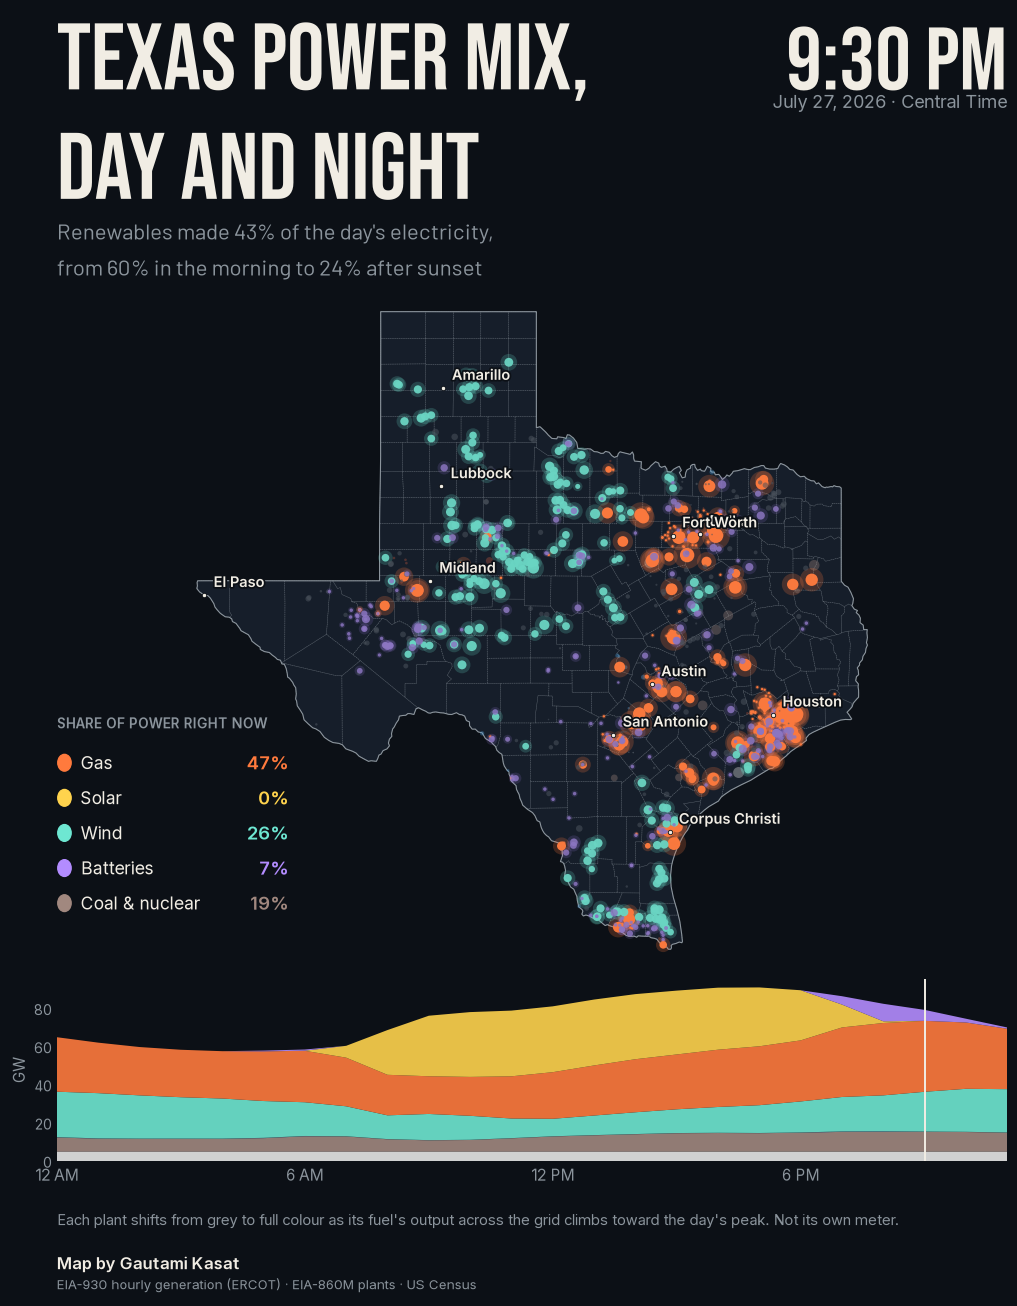

In [5]:
F = poster.font
TITLE_F, TEXT_F, TEXT_B = poster.BEBAS, poster.SANS, poster.SANS_BOLD
SUB_F = poster.BARLOW                    # a narrower face for the subtitle paragraph

w, s, e, n_ = texas.total_bounds
ASPECT = 1 / np.cos(np.radians((s + n_) / 2))
PEAK = d[fuel_cols].clip(lower=0).max()      # each fuel's highest output today
from matplotlib.colors import to_rgb
import textwrap

def at(t):
    """Values at fractional hour index t (0 = first hour's middle), by linear interpolation."""
    i = int(np.clip(np.floor(t), 0, len(d) - 2)); f = t - i
    row = d.loc[i, fuel_cols] * (1 - f) + d.loc[i + 1, fuel_cols] * f
    when = d.mid[i] + (d.mid[i + 1] - d.mid[i]) * f
    return row, when

def draw(t):
    row, when = at(t)
    fig = plt.figure(figsize=(10.8, 13.5), dpi=100, facecolor=PAGE)
    ax = fig.add_axes([0.02, 0.26, 0.96, 0.49], facecolor=PAGE)
    texas.plot(ax=ax, color=LAND, lw=0, zorder=1)
    tx_counties.boundary.plot(ax=ax, color=SOFT, lw=0.3, alpha=0.5, linestyle="--", zorder=2)
    texas.boundary.plot(ax=ax, color=SOFT, lw=0.8, zorder=2)
    for fuel, col in OTHER.items():
        p = shown[shown.fuel == fuel]
        ax.scatter(p.lon, p.lat, s=np.sqrt(p.mw) * 1.2, color=col, alpha=0.35, lw=0, zorder=3)
    for fuel, (col, _) in FUELS.items():
        if fuel not in row:
            continue
        p = shown[shown.fuel == fuel]
        k = float(np.clip(row[fuel] / PEAK.get(fuel, np.inf), 0, 1))     # 0 = resting, 1 = the day's peak
        now = tuple(np.array(to_rgb(IDLE)) * (1 - k) + np.array(to_rgb(col)) * k)
        base = np.sqrt(p.mw)
        ax.scatter(p.lon, p.lat, s=base * (1.5 + 8 * k), color=col, alpha=0.22 * k, lw=0, zorder=5)    # glow
        ax.scatter(p.lon, p.lat, s=base * (1.0 + 1.6 * k), color=now, alpha=0.55 + 0.45 * k, lw=0, zorder=6)
    ax.set_xlim(w - 0.2, e + 0.2); ax.set_ylim(s - 0.2, n_ + 0.2); ax.set_aspect(ASPECT); ax.set_axis_off()

    # title and clock
    fig.text(0.06, 0.965, TITLE.upper(), color=INK, fontproperties=F(TITLE_F, 68), va="top", linespacing=0.92)
    fig.text(0.06, 0.812, textwrap.fill(SUBTITLE, SUBTITLE_WIDTH), color=SOFT, fontproperties=F(SUB_F, 16),
             va="top", ha="left", linespacing=1.35)
    local = pd.Timestamp(when).tz_localize("UTC").tz_convert("America/Chicago")
    fig.text(0.94, 0.965, clock(local), color=INK, fontproperties=F(TITLE_F, 64), ha="right", va="top")
    fig.text(0.94, 0.905, f"{STATS['date']} · Central Time", color=SOFT, fontproperties=F(TEXT_F, 13), ha="right", va="top")

    # cities, so people can find their way
    for name, (la, lo) in CITIES.items():
        ax.scatter([lo], [la], s=10, color=INK, edgecolor=PAGE, lw=0.6, zorder=8)
        poster.halo_text(ax, lo + 0.18, la + 0.08, name, color=INK, path=TEXT_B, size=10.5, halo=PAGE, halo_width=2.5,
                         ha="left", va="bottom", zorder=9)

    # legend in the map's lower-left corner, with this moment's share of power
    tot = row.clip(lower=0).sum()
    items = [(col, lab, max(row.get(f, 0), 0)) for f, (col, lab) in FUELS.items()]
    items.append((OTHER["Coal"], "Coal & nuclear", sum(max(row.get(f, 0), 0) for f in ("Coal", "Nuclear"))))
    lx, ly = 0.06, 0.40
    fig.text(lx, ly + 0.03, "SHARE OF POWER RIGHT NOW", color=SOFT, fontproperties=F(TEXT_B, 10), va="bottom")
    for i, (col, lab, val) in enumerate(items):
        y = ly - i * 0.026
        fig.add_artist(plt.matplotlib.patches.Circle((lx + 0.007, y + 0.007), 0.0062, transform=fig.transFigure, color=col))
        fig.text(lx + 0.022, y + 0.007, lab, color=INK, fontproperties=F(TEXT_F, 12.5), va="center")
        fig.text(lx + 0.215, y + 0.007, f"{val / tot * 100:.0f}%", color=col, fontproperties=F(TEXT_B, 13), va="center", ha="right")

    # the day as a stacked chart, with a line for now
    cx = fig.add_axes([0.06, 0.112, 0.88, 0.135], facecolor=PAGE)
    order = [f for f in ["Nuclear", "Coal", "Hydro", "Other", "Oil", "Wind", "Gas", "Solar", "Storage"] if f in d]
    cols = [FUELS.get(f, (OTHER.get(f, SOFT),))[0] for f in order]
    hrs = np.arange(len(d))
    cx.stackplot(hrs, *[d[f].clip(lower=0) / 1000 for f in order], colors=cols, alpha=0.9, lw=0)
    cx.axvline(t, color=INK, lw=1.4)
    cx.set_xlim(0, len(d) - 1); cx.set_ylim(0, None)
    cx.set_xticks([i for i in hrs if d.local[i].hour % 6 == 0])
    cx.set_xticklabels([clock(d.local[i], False) for i in hrs if d.local[i].hour % 6 == 0], color=SOFT,
                       fontproperties=F(TEXT_F, 11))
    cx.tick_params(axis="y", colors=SOFT, labelsize=10, length=0); cx.tick_params(axis="x", length=0)
    for sp in cx.spines.values():
        sp.set_visible(False)
    cx.set_ylabel("GW", color=SOFT, fontproperties=F(TEXT_F, 11))
    for lab in cx.get_yticklabels():
        lab.set_fontproperties(F(TEXT_F, 10))

    fig.text(0.06, 0.075, "Each plant shifts from grey to full colour as its fuel's output across the grid climbs toward "
             "the day's peak. Not its own meter.", color=SOFT, fontproperties=F(TEXT_F, 10.5), va="top")
    poster.credit(fig, "EIA-930 hourly generation (ERCOT) · EIA-860M plants · US Census", x=0.06, y=0.012, color=SOFT,
                  path=TEXT_F, name_path=TEXT_B, name_color=INK, size=9.5)
    return fig

fig = draw(float(gas_peak))
plt.show()

## 5 · Export: MP4 for LinkedIn, a GIF for GitHub and your portfolio, and a still at 8:30 PM

frame 0 of 238
frame 20 of 238
frame 40 of 238
frame 60 of 238
frame 80 of 238
frame 100 of 238
frame 120 of 238
frame 140 of 238
frame 160 of 238
frame 180 of 238
frame 200 of 238
frame 220 of 238
saved D:\00_MUSA_EVERTHING\30-day-map-challenge-2026\output\day17_light-dark-texas-grid.mp4 and D:\00_MUSA_EVERTHING\30-day-map-challenge-2026\output\day17_light-dark-texas-grid.gif
map        output/day17_light-dark-texas-grid.png
thumbnail  png_thumbnail/day17_light-dark-texas-grid.png
caption    captions/day17_light-dark-texas-grid.md
live link  https://gautamik01.github.io/30-day-map-challenge-2026/output/day17_light-dark-texas-grid.png  (after you push)


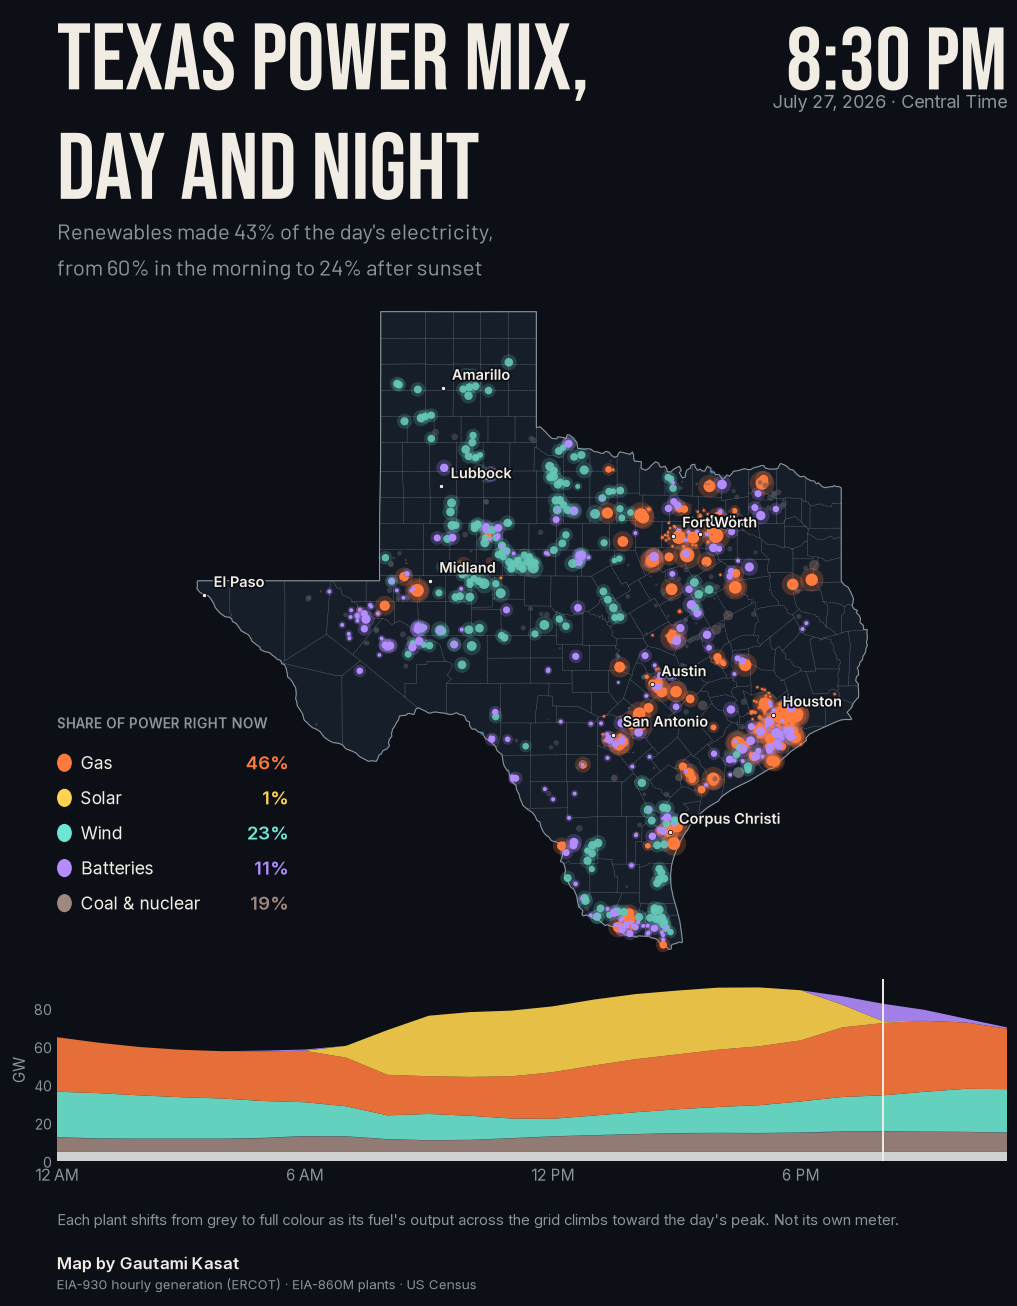

In [6]:
import io, imageio_ffmpeg          # pip install imageio-ffmpeg (if missing)
from PIL import Image
from mapkit.paths import OUTPUT

ts = np.arange(0, len(d) - 1 + 1e-9, 1 / PER_HOUR)
ts = np.r_[ts, [ts[-1]] * int(HOLD * FPS)]
mp4 = OUTPUT / f"day{DAY:02d}_{SLUG}.mp4"
gif = OUTPUT / f"day{DAY:02d}_{SLUG}.gif"
small = []                                                   # half-size frames for the GIF
out = None
for k, t in enumerate(ts):
    f = draw(t)
    buf = io.BytesIO(); f.savefig(buf, format="png", facecolor=PAGE); plt.close(f)
    im = Image.open(buf).convert("RGB")
    if out is None:                                         # open the video once we know the frame size
        out = imageio_ffmpeg.write_frames(str(mp4), im.size, fps=FPS, codec="libx264", pix_fmt_out="yuv420p",
                                          output_params=["-crf", "18", "-preset", "veryfast"], macro_block_size=1)
        out.send(None)
    out.send(np.array(im).tobytes())
    small.append(im.resize((540, 675), Image.LANCZOS).quantize(colors=128, method=Image.Quantize.MEDIANCUT))
    if k % 20 == 0:
        print(f"frame {k} of {len(ts)}")
out.close()
small[0].save(gif, save_all=True, append_images=small[1:], duration=int(1000 / FPS), loop=0, optimize=True)
print("saved", mp4, "and", gif)

still = draw(float(batt_peak))
publish.save(still, day=DAY, slug=SLUG, prompt=PROMPT, title=TITLE.replace("\n", " "),
             subtitle=SUBTITLE,
             series="ai", tool="Python", notebook=NOTEBOOK, credits=CREDITS)